# CatBoost for concrete strength classification

In this notebook, we repeat the concrete strength classification exercise (already seen with linear discriminant analysis, logistic regression, and support vector machines) using **CatBoost**. Rather than predicting compressive strength from a regression perspective, we discretize the target variable into three strength classes:
- Low strength: $f_c < 25\ \text{MPa}$
- Medium strength: $25 \leq f_c \leq 40\ \text{MPa}$
- High strength: $f_c > 40\ \text{MPa}$

We then reformulate the original regression problem as a multiclass classification problem. CatBoost is a gradient-boosting algorithm based on decision trees. It builds an ensemble of trees sequentially, with each new tree helping to correct errors made by the current ensemble.

Unlike SVMs, tree-based methods do not rely on distances or inner products between features. Therefore, feature standardization is generally not required. We will examine the influence of the main model hyperparameters and use feature importance to investigate which input variables contribute most to the classification.

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, accuracy_score

from catboost import CatBoostClassifier

### Load data

The dataset contains:
- Input variables describing the concrete composition
- One target variable corresponding to the concrete compressive strength

In [3]:
# Load data from Excel
file_path = "../../Data/Concrete/Concrete.xls"
df = pd.read_excel(file_path)
# The dataset is stored in Excel format (.xls).
# Pandas requires the 'xlrd' package to read this format.
# If you get an error, install it via: pip install xlrd.

# Display the first rows of the dataset
df.head()

/var/folders/3s/_n9qz1fn1c16ps0d1l7d45300000gn/T/ipykernel_80818/2513056146.py:3: Pandas4Warning: The xlrd engine is deprecated and will be removed in a future version. Use the calamine engine instead, by setting engine='calamine'.
  df = pd.read_excel(file_path)


,Cement (component 1)(kg in a m^3 mixture),Blast Furnace Slag (component 2)(kg in a m^3 mixture),Fly Ash (component 3)(kg in a m^3 mixture),Water (component 4)(kg in a m^3 mixture),Superplasticizer (component 5)(kg in a m^3 mixture),Coarse Aggregate (component 6)(kg in a m^3 mixture),Fine Aggregate (component 7)(kg in a m^3 mixture),Age (day),"Concrete compressive strength(MPa, megapascals)"
0,540.0,0.0,0.0,162.0,2.5,1040.0,676.0,28,79.986111
1,540.0,0.0,0.0,162.0,2.5,1055.0,676.0,28,61.887366
2,332.5,142.5,0.0,228.0,0.0,932.0,594.0,270,40.269535
3,332.5,142.5,0.0,228.0,0.0,932.0,594.0,365,41.052780
4,198.6,132.4,0.0,192.0,0.0,978.4,825.5,360,44.296075


In [4]:
# In this dataset, the last column is the concrete compressive strength target
X = df.iloc[1:, :-1].values # All columns except last → input features
y = df.iloc[1:, -1].values # Last column → target

N, d = X.shape

print("Input shape:", X.shape)
print("Target shape:", y.shape)
print(f"Number of samples: {N}")
print(f"Number of input features: {d}")

Input shape: (1029, 8)
Target shape: (1029,)
Number of samples: 1029
Number of input features: 8


### Convert compressive strength into strength classes

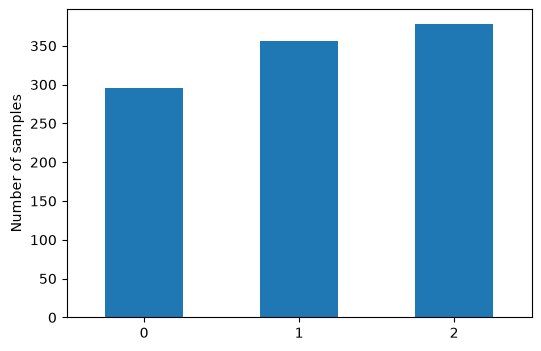

In [5]:
# Strength intervals (MPa)
class_names = ["Low strength", "Medium strength", "High strength",]

# Explicit conditions implement the class definitions:
# Low: fc < 25; Medium: 25 <= fc <= 40; High: fc > 40
y_class = np.select([y < 25, (y >= 25) & (y <= 40), y > 40],[0, 1, 2])

plt.figure(figsize=(6, 4))
pd.Series(y_class).value_counts().sort_index().plot.bar()
plt.ylabel("Number of samples")
plt.xticks(rotation=0)
plt.show()

### Split the data

We split the dataset into training and test sets, using 80% of the observations for training and 20% for testing. Stratification preserves approximately the same class proportions in both sets.

Unlike SVMs, CatBoost uses decision trees and does not require feature standardization. We therefore use the original input variables.

In [6]:
# Split data (80% train, 20% test)
X_train, X_test, y_train, y_test = train_test_split(X, y_class, test_size=0.2, random_state=4, stratify=y_class)

### Train a CatBoost classifier

CatBoost constructs an ensemble of decision trees sequentially. At each boosting iteration, a new tree is fitted to improve the predictions of the current ensemble.

The main hyperparameters are:

- `iterations`: number of boosting iterations (trees).
- `depth`: maximum depth of each tree.
- `learning_rate`: contribution of each new tree to the ensemble.

We begin with a baseline model. The `verbose=False` option suppresses the training log.

In [7]:
catboost = CatBoostClassifier(
    loss_function="MultiClass",
    iterations=500,
    depth=6,
    learning_rate=0.05,
    random_seed=4,
    verbose=False
)

catboost.fit(X_train, y_train)

CatBoostClassifier(depth=6, iterations=500, learning_rate=0.05, loss_function='MultiClass', random_seed=4, verbose=False)

### Prediction and visualization

The performance of a classifier can be evaluated by comparing its predictions with the ground-truth labels. A confusion matrix summarizes the classification results, while accuracy measures the proportion of correctly classified samples.

The confusion matrix below is normalized by row, so each row reports the fraction of observations belonging to a given true class that are assigned to each predicted class.

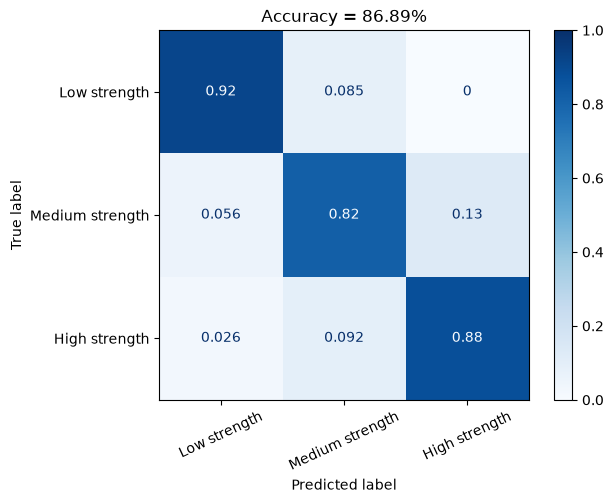

In [8]:
y_pred = catboost.predict(X_test).ravel().astype(int)
accuracy = accuracy_score(y_test, y_pred)

cm = confusion_matrix(y_test, y_pred, normalize="true")
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=class_names)

disp.plot(cmap="Blues", xticks_rotation=25)
disp.im_.set_clim(0, 1)
plt.title(f"Accuracy = {accuracy:.2%}")
plt.show()

### Feature importance

We can inspect feature importance, which provides an indication of how much each input variable contributes to the fitted model. Specifically, it provides a model-dependent measure of predictive contribution.

CatBoost's default feature importance for a classification model is based on the change in the model's prediction loss associated with each feature. The values are normalized to sum to 100.

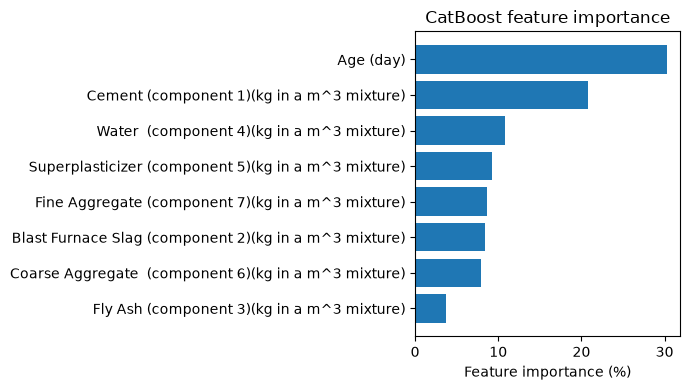

In [9]:
importance = catboost.get_feature_importance()
feature_names = df.columns

order = np.argsort(importance)

plt.figure(figsize=(7, 4))
plt.barh(np.array(feature_names)[order], importance[order])
plt.xlabel("Feature importance (%)")
plt.title("CatBoost feature importance")
plt.tight_layout()
plt.show()

### Influence of the number of boosting iterations

The parameter `iterations` controls the number of trees added to the ensemble. Increasing the number of iterations can improve the fit, although adding too many trees may lead to overfitting. We compare test accuracy for a few values of `iterations`, keeping the other hyperparameters fixed.

In [10]:
iteration_values = [50, 100, 250, 500, 750, 1000, 2000, 3000, 5000, 10000]

for n_iter in iteration_values:
    model = CatBoostClassifier(
        loss_function="MultiClass",
        iterations=n_iter,
        depth=6,
        learning_rate=0.05,
        random_seed=4,
        verbose=False
    )

    model.fit(X_train, y_train)
    acc = accuracy_score(y_test, model.predict(X_test).ravel())

    print(f"Iterations = {n_iter:>3}:   Accuracy = {acc:.2%}")


Iterations =  50:   Accuracy = 79.61%
Iterations = 100:   Accuracy = 80.58%
Iterations = 250:   Accuracy = 83.50%
Iterations = 500:   Accuracy = 86.89%
Iterations = 750:   Accuracy = 87.38%
Iterations = 1000:   Accuracy = 88.83%
Iterations = 2000:   Accuracy = 89.32%
Iterations = 3000:   Accuracy = 88.83%
Iterations = 5000:   Accuracy = 88.83%
Iterations = 10000:   Accuracy = 88.35%


### Influence of tree depth and learning rate

The parameter `depth` controls the complexity of individual trees. Shallow trees capture relatively simple interactions, whereas deeper trees can represent more complex relationships but may be more prone to overfitting.

The `learning_rate` controls the contribution of each successive tree. Smaller values generally require more boosting iterations, while larger values may lead to faster fitting but can reduce generalization performance.

The following experiment compares a few combinations of these hyperparameters. For a fair comparison, the train–test split and random seed are kept fixed.

In [11]:
depth_values = [4, 6, 8]
learning_rates = [0.01, 0.05, 0.1]

for depth in depth_values:
    for lr in learning_rates:
        model = CatBoostClassifier(
            loss_function="MultiClass",
            iterations=1000,
            depth=depth,
            learning_rate=lr,
            random_seed=4,
            verbose=False
        )

        model.fit(X_train, y_train)
        y_pred = model.predict(X_test).ravel()
        acc = accuracy_score(y_test, y_pred)

        print(f"Depth = {depth}, learning rate = {lr:.2f}: " 
              f"Accuracy = {acc:.2%}")

Depth = 4, learning rate = 0.01: Accuracy = 83.98%
Depth = 4, learning rate = 0.05: Accuracy = 87.86%
Depth = 4, learning rate = 0.10: Accuracy = 88.83%
Depth = 6, learning rate = 0.01: Accuracy = 83.50%
Depth = 6, learning rate = 0.05: Accuracy = 88.83%
Depth = 6, learning rate = 0.10: Accuracy = 88.83%
Depth = 8, learning rate = 0.01: Accuracy = 85.44%
Depth = 8, learning rate = 0.05: Accuracy = 89.81%
Depth = 8, learning rate = 0.10: Accuracy = 88.35%


### Exercises

- Compare the classification accuracy obtained using LDA, Logistic Regression, SVM, and CatBoost. Are the results consistent across the different methods?
  
- Investigate the influence of `iterations`, `depth`, and `learning_rate` on the test accuracy.

- Compare the feature-importance ranking with the physical interpretation of the concrete composition variables. Which variables are most informative?

- Repeat the experiment using a different train–test split. How sensitive are the results to the particular observations assigned to the test set?


In [12]:
# CatBoost for concrete strength regression

We can use CatBoost also to predict the compressive strength of concrete directly from its mix-design variables, as we attempted to do through linear regression. The target is kept as a continuous variable, measured in MPa.

In [13]:
# Split data (80% train, 20% test)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=4, stratify=y_class)

### Train a CatBoost regressor

For regression, the model minimizes a loss function measuring the discrepancy between predicted and observed target values. A possible optio for the training loss is the root mean squared error (RMSE)

In [15]:
from catboost import CatBoostRegressor

catboost = CatBoostRegressor(
    loss_function="RMSE",
    iterations=1000,
    depth=6,
    learning_rate=0.05,
    random_seed=4,
    verbose=False
)

catboost.fit(X_train, y_train)

CatBoostRegressor(depth=6, iterations=1000, learning_rate=0.05, loss_function='RMSE', random_seed=4, verbose=False)

We evaluate the regression model using the mean squared error (MSE) and the coefficient of determination $R^2$.

In [19]:
from sklearn.metrics import mean_squared_error, r2_score

y_pred = catboost.predict(X_test)

mse = mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print(f"MSE:  {mse:.2f} MPa")
print(f"R²:   {r2:.3f}")

MSE:  14.40 MPa
R²:   0.954


In [20]:
def parity_plot(y_true, y_pred, title="Parity Plot"):
    plt.figure()
    
    # Scatter plot: true vs predicted
    #plt.scatter(y_true, y_pred, s=80, c='k', marker='x', linewidth=0.7, zorder=1)

    # For large datasets, individual scatter points may overlap, making it difficult to assess the distribution of predictions. 
    # Hexagonal binning addresses this issue by grouping points into bins and visualizing their frequency through color intensity. 
    # The associated colorbar indicates the number of samples within each bin.
    hb = plt.hexbin(y_true, y_pred, zorder=-1, cmap='gray_r', mincnt=1, gridsize=12, edgecolors='none')
    cb = plt.colorbar(hb)
    cb.set_label("Counts per bin")
    
    # Ideal line (perfect prediction)
    min_val = min(np.min(y_true), np.min(y_pred))
    max_val = max(np.max(y_true), np.max(y_pred))
    plt.plot([min_val, max_val], [min_val, max_val], 'goldenrod', linewidth=1.5, zorder=1, linestyle='--')

    plt.xlim([min_val, max_val])
    plt.ylim([min_val, max_val])
    plt.xlabel("True strength [MPa]")
    plt.ylabel("Predicted strength [MPa]")
    plt.title(title)

    # Mean squarred error
    mse = np.mean((y_true - y_pred)**2)
    # R^2 score (coefficient of determination)
    r2 = 1 - np.sum((y_true - y_pred)**2) / np.sum((y_true - np.mean(y_true))**2)
    
    plt.text(min_val, max_val, f"MSE = {mse:.3f}\nR² = {r2:.3f}",
             verticalalignment='top')
    
    plt.show()

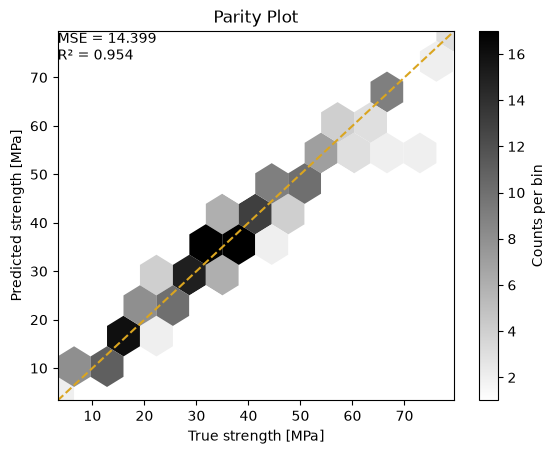

In [22]:
parity_plot(y_test, y_pred)